# Phase 2 — Model training
Predict Churn (Yes = 1). We compare Logistic Regression, Random Forest, and XGBoost using five-fold stratified cross-validation on the training set. The highest mean CV ROC-AUC selects the model before we inspect test results.

The test split is held out from fitting and selection here. Phase 1 inspected the full dataset, so this is not a completely untouched external validation cohort. No Streamlit application is created.

In [1]:
from pathlib import Path
import sys, json, platform, importlib.util, hashlib
ROOT = Path.cwd()
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent
# Optional project-local dependency installed for this execution.
if importlib.util.find_spec("xgboost") is None and (ROOT / ".phase2_packages").exists():
    sys.path.insert(0, str(ROOT / ".phase2_packages"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost, joblib
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
SEED = 42
sns.set_theme(style="whitegrid")
MODEL_DIR = ROOT / "models"
REPORT_DIR = ROOT / "reports"
MODEL_DIR.mkdir(exist_ok=True)
(REPORT_DIR / "figures").mkdir(parents=True, exist_ok=True)
print("Versions:", sklearn.__version__, xgboost.__version__)

Versions: 1.7.2 3.4.1


## 1. Load and clean
Use the raw data, not the Phase 1 complete-case subset. Whitespace cleanup and numeric conversion are deterministic. Missing TotalCharges values are retained for training-fold median imputation. Customer IDs and both representations of the target are excluded from features. Service absence categories are valid categories, not missing values.

In [2]:
path = ROOT / "data" / "raw" / "Telco-Customer-Churn.txt"
raw = pd.read_csv(path, na_values=["", " "])
data = raw.copy()
for col in data.select_dtypes(include=["object", "string"]):
    data[col] = data[col].str.strip().replace("", np.nan)
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
data = data.drop_duplicates()
assert data["customerID"].is_unique, "Resolve repeated customer IDs before splitting."
assert data["Churn"].notna().all() and set(data["Churn"].unique()) == {"No", "Yes"}
y = data["Churn"].map({"No": 0, "Yes": 1})
X = data.drop(columns=["customerID", "Churn", "ChurnFlag"], errors="ignore")
assert not {"customerID", "Churn", "ChurnFlag"}.intersection(X.columns)
print("Rows:", len(X), "| Features:", X.shape[1])
display(X.isna().sum().loc[lambda s: s > 0].to_frame("missing"))
display(y.value_counts().rename(index={0: "Stayed", 1: "Churned"}).to_frame("customers"))

Rows: 7043 | Features: 19


,missing
TotalCharges,11


,customers
Churn,
Stayed,5174
Churned,1869


## 2. Stratified 80/20 split and preprocessing
Stratification preserves roughly the same churn proportion in each split. Numeric columns are median-imputed and standardized. Categorical columns are imputed with the most frequent value and one-hot encoded; unseen categories are tolerated. Every transformer is inside each model pipeline so cross-validation fits it only on that fold's training rows.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
numeric = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical = [c for c in X.columns if c not in numeric]
def make_preprocessor():
    return ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), numeric),
        ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                  ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical)])
print(f"Training: {len(X_train):,}; test: {len(X_test):,}")
print(f"Churn proportion — train: {y_train.mean():.2%}; test: {y_test.mean():.2%}")

Training: 5,634; test: 1,409
Churn proportion — train: 26.54%; test: 26.54%


## 3. Models and class imbalance
Logistic Regression and Random Forest use balanced class weights, calculated on each fit. XGBoost receives balanced sample weights: misclassifying the minority class has greater cost. Its per-fold weights are derived from that fold's training labels. We do not resample or weight the validation/test observations.

These are reproducible baseline configurations, not a hyperparameter search. All classification metrics use a fixed probability threshold of 0.5; ROC-AUC evaluates ranking across thresholds.

In [4]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
        class_weight="balanced", random_state=SEED, n_jobs=2),
    "XGBoost": XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
        tree_method="hist", random_state=SEED, n_jobs=2)
}
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def metrics(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, prob)}
fold_rows = []
for name, estimator in models.items():
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), 1):
        pipe = Pipeline([("preprocess", make_preprocessor()), ("model", clone(estimator))])
        fit_args = {}
        if name == "XGBoost":
            fit_args["model__sample_weight"] = compute_sample_weight(
                class_weight="balanced", y=y_train.iloc[train_idx])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx], **fit_args)
        prob = pipe.predict_proba(X_train.iloc[val_idx])[:, 1]
        fold_rows.append({"model": name, "fold": fold, **metrics(y_train.iloc[val_idx], prob)})
    print(name, "— five folds complete")
fold_scores = pd.DataFrame(fold_rows)
cv_summary = fold_scores.groupby("model")[["precision", "recall", "f1", "roc_auc"]].agg(["mean", "std"])
cv_summary = cv_summary.sort_values(("roc_auc", "mean"), ascending=False)
display(cv_summary.round(4))
best_name = cv_summary.index[0]
print("Selected by mean CV ROC-AUC:", best_name)
fold_scores.to_csv(REPORT_DIR / "phase2_cv_scores.csv", index=False)

Logistic Regression — five folds complete


Random Forest — five folds complete


XGBoost — five folds complete


precision          recall              f1         roc_auc  \
                         mean     std    mean     std    mean     std    mean   
model                                                                           
XGBoost                0.5273  0.0160  0.7967  0.0320  0.6344  0.0194  0.8478   
Logistic Regression    0.5174  0.0210  0.8013  0.0424  0.6286  0.0260  0.8460   
Random Forest          0.5955  0.0287  0.6448  0.0319  0.6189  0.0262  0.8371   

                             
                        std  
model                        
XGBoost              0.0118  
Logistic Regression  0.0138  
Random Forest        0.0115

Selected by mean CV ROC-AUC: XGBoost


## 4. Fit the selected model and evaluate once on the test set
The winner is now fixed. Fit its complete pipeline on all training rows, then calculate precision (how many churn alerts are correct), recall (how many churners are detected), F1 (a balance of precision and recall), and ROC-AUC (ranking performance). We do not select or tune a model using these test results.

,precision,recall,f1,roc_auc
XGBoost,0.5147,0.7941,0.6246,0.8455


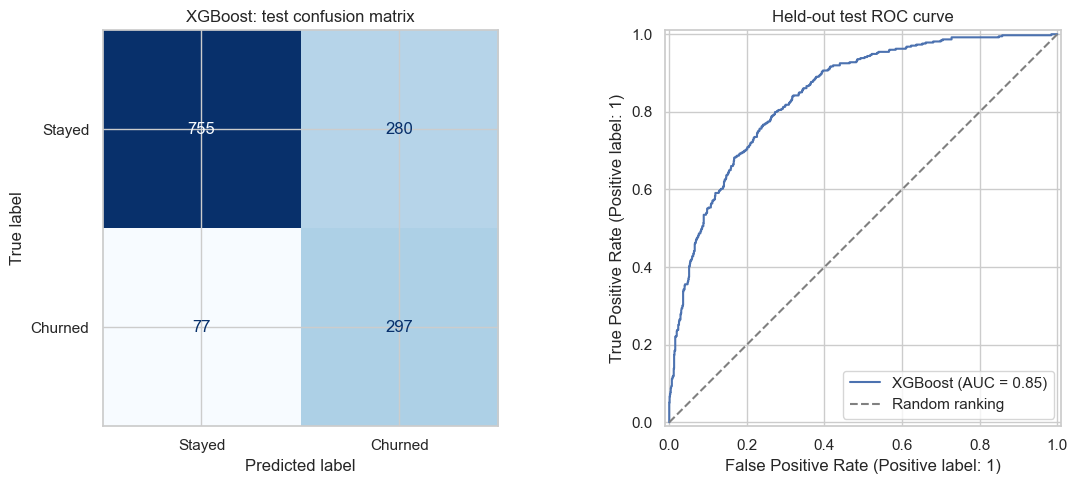

In [5]:
best_pipeline = Pipeline([("preprocess", make_preprocessor()), ("model", clone(models[best_name]))])
fit_args = {}
if best_name == "XGBoost":
    fit_args["model__sample_weight"] = compute_sample_weight("balanced", y_train)
best_pipeline.fit(X_train, y_train, **fit_args)
test_prob = best_pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
test_metrics = metrics(y_test, test_prob)
display(pd.DataFrame([test_metrics], index=[best_name]).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=[0, 1],
    display_labels=["Stayed", "Churned"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"{best_name}: test confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_prob, name=best_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[1].legend()
axes[1].set_title("Held-out test ROC curve")
fig.tight_layout()
fig.savefig(REPORT_DIR / "figures" / "phase2_test_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Save and verify the best pipeline
The artifact contains preprocessing and the classifier together. It expects the raw feature columns after the deterministic cleanup above, including numeric conversion of TotalCharges. It is fitted on the 80% training split only. Load joblib files only from trusted sources.

In [6]:
model_path = MODEL_DIR / "best_churn_pipeline.joblib"
joblib.dump(best_pipeline, model_path)
(MODEL_DIR / "artifact.sha256").write_text(hashlib.sha256(model_path.read_bytes()).hexdigest() + "\n", encoding="utf-8")
loaded = joblib.load(model_path)
np.testing.assert_allclose(loaded.predict_proba(X_test)[:, 1], test_prob)
metadata = {
    "selected_model": best_name, "selection_metric": "mean five-fold training CV ROC-AUC",
    "cv_roc_auc": float(cv_summary.loc[best_name, ("roc_auc", "mean")]),
    "test_metrics": test_metrics, "threshold": 0.5, "seed": SEED,
    "train_rows": len(X_train), "test_rows": len(X_test),
    "feature_columns": X.columns.tolist(),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "xgboost": xgboost.__version__, "pandas": pd.__version__, "joblib": joblib.__version__}
}
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved and reload-verified:", model_path.relative_to(ROOT).as_posix())
print(f"{best_name} won CV with ROC-AUC {metadata['cv_roc_auc']:.3f}.")
print(f"Test precision {test_metrics['precision']:.3f}, recall {test_metrics['recall']:.3f}, "
      f"F1 {test_metrics['f1']:.3f}, ROC-AUC {test_metrics['roc_auc']:.3f}.")
print("Class weighting prioritizes minority churners, potentially increasing false alarms.")
print("CV standard deviations describe fold variability, not confidence intervals.")
print("Future threshold tuning should use training validation data and retention costs, not this test set.")

Saved and reload-verified: models/best_churn_pipeline.joblib
XGBoost won CV with ROC-AUC 0.848.
Test precision 0.515, recall 0.794, F1 0.625, ROC-AUC 0.846.
Class weighting prioritizes minority churners, potentially increasing false alarms.
CV standard deviations describe fold variability, not confidence intervals.
Future threshold tuning should use training validation data and retention costs, not this test set.
